# <span style="color:darkblue"> Lecture 18: PCA and K-means clustering </span>


<font size = "5">


PCA:

https://www.youtube.com/watch?v=nEvKduLXFvk

K-means clustering:

https://www.youtube.com/watch?v=R2e3Ls9H_fc

# <span style="color:darkblue"> I. Setup Working Environment </span>

Install the faiss-CPU package for fast kmeans clustering

<font size = "5">

``` conda install -c conda-forge faiss-cpu ```

In [1]:
# Import the package for the University of California Irvine API
from ucimlrepo import fetch_ucirepo 

# Import SK-Learn library for machine learning functions
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import cross_validate
from sklearn import preprocessing
from sklearn.metrics import get_scorer_names

# Import PCA
from sklearn.decomposition import PCA


# Import standard data analysis packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Import Kmeans
from sklearn.cluster import MiniBatchKMeans

import faiss


# <span style="color:darkblue"> II. Data </span>

<font size = "5">

Cancer screening dataset


In [2]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
cancer = load_breast_cancer()

X = cancer.data
y = cancer.target

X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    random_state=0)
print(X_train.shape)
print(X_test.shape)

(426, 30)
(143, 30)


<font size = "5">

Check features

In [3]:
cancer.feature_names

array(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error',
       'fractal dimension error', 'worst radius', 'worst texture',
       'worst perimeter', 'worst area', 'worst smoothness',
       'worst compactness', 'worst concavity', 'worst concave points',
       'worst symmetry', 'worst fractal dimension'], dtype='<U23')

# <span style="color:darkblue"> III. Principal Components Analysis </span>


<font size = "5">

A factor is a linear combination of the columns of $X$

$F = X \omega$

We call $\omega \in \mathbb{R}^K$ the factor loadings.

- More factors can describe the data better
- Fewer factors reduce dimensionality, i.e. regularize.
- Principal Components Analysis (PCA) is an algorithm <br>
to obtain factors.


<font size = "5">

Intuition: The first factor solves

$ \quad \omega_1 = \arg\max_{\omega \in \mathbb{R}^K} \frac{\omega^TX^TX\omega}{\omega^T\omega} $

$F_i^{FIRST} = \sum_{k=1}^K \omega_k^{FIRST} X_{ik}$

- This tries to compute the most variation in $X$
- The second factor solves a similar problem, with the $X$ residual <br>
not explained by the first factor

In [4]:
# Choose number of components

pca = PCA(n_components=3)
# fit PCA model to beast cancer data
pca.fit(X_train)

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",3
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized SVD 

<font size = "5">

We can check the loadings for each factor

In [5]:
# pca_components_ has the factor loadings
factor_loadings = pd.DataFrame(pca.components_,
                               columns = cancer.feature_names)

factor_loadings

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,0.004985,0.001995,0.034312,0.514386,0.000004,0.000038,0.000077,0.000046,0.000006,-0.000003,...,0.007043,0.002836,0.048654,0.853525,0.000006,0.000094,0.000152,0.000070,0.000016,0.000001
1,0.008863,-0.003974,0.059971,0.852528,-0.000012,-0.000004,0.000077,0.000046,-0.000020,-0.000014,...,-0.000811,-0.015200,-0.002298,-0.518050,-0.000071,-0.000258,-0.000171,-0.000032,-0.000153,-0.000052
2,-0.012357,-0.005176,-0.072924,-0.047779,0.000068,0.000075,0.000247,0.000019,0.000116,0.000045,...,-0.015658,-0.027245,-0.095353,-0.028912,-0.000038,-0.000714,-0.000724,-0.000336,-0.000338,-0.000034


<font size = "5">

A way to visualize loadings

Text(0, 0.5, 'Principal components')

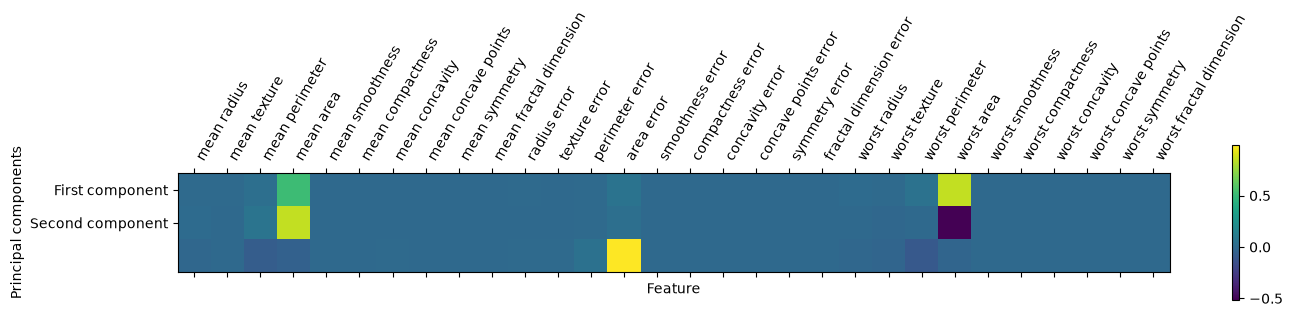

In [6]:
plt.matshow(pca.components_, cmap='viridis')
plt.yticks([0,  1], ["First component", "Second component"])
plt.colorbar()
plt.xticks(range(len(cancer.feature_names)),
           cancer.feature_names, rotation=60, ha='left')
plt.xlabel("Feature")
plt.ylabel("Principal components")


<font size = "5">

Compute factors

In [7]:
# transform data onto the first two principal components

X_pca = pca.transform(X_train)


<font size = "5">

Are factors useful for prediction?

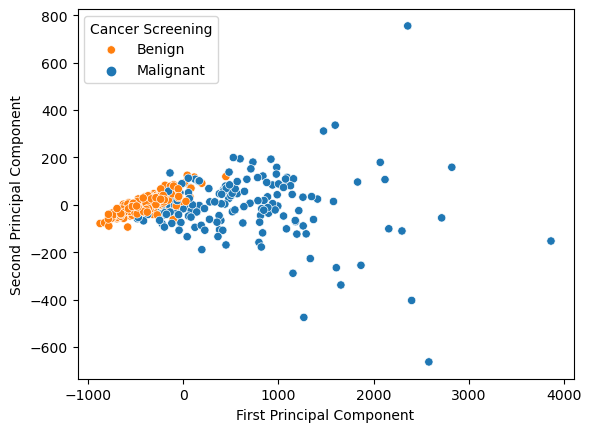

In [8]:
# Hue is used to color

ax = sns.scatterplot(x = X_pca[:,0],
                     y = X_pca[:,1],
                     hue = y_train)
ax.set(xlabel='First Principal Component',
       ylabel='Second Principal Component')
ax.legend(title='Cancer Screening', loc='upper left', labels=
                      ["Benign","Malignant"])


<font size = "5">

Try it yourself

- PCA can be sensitive to the way the data is processed
- Demean and scale the $X$ variables using the techniques we covered <br>
in the previous classes.
- What changes?

Note: The units of each factor can change. <br>
Therefore, it is better not to interpret <br>
PCA factors directly, but just view them as an intermediate <br>
dimensionality reduction step for further analyses

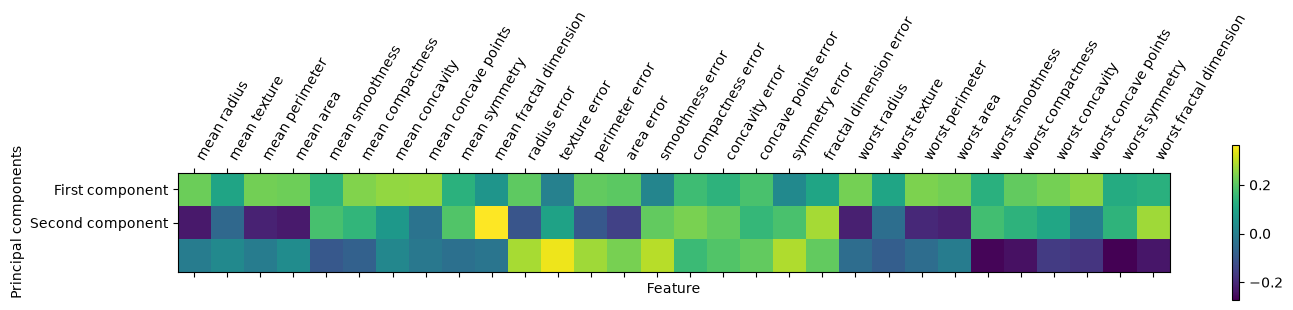

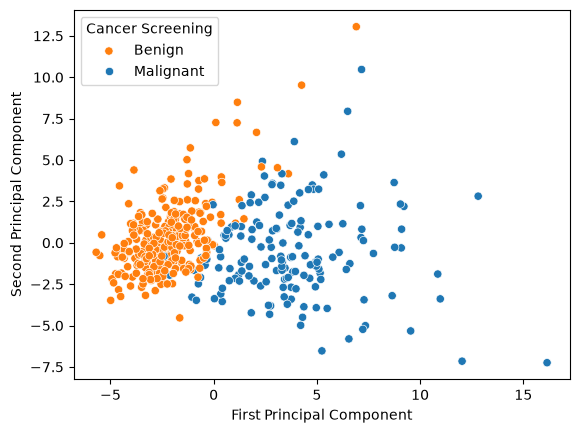

In [8]:
# Write your own code

# The first step is to produce a "scaler" function
scaler_train = preprocessing.StandardScaler().fit(X_train)

# Apply scaler function
X_train_scale = scaler_train.transform(X_train)


pca = PCA(n_components=3)
# fit PCA model to beast cancer data
pca.fit(X_train_scale)

# pca_components_ has the factor loadings
factor_loadings = pd.DataFrame(pca.components_,
                               columns = cancer.feature_names)

factor_loadings

plt.matshow(pca.components_, cmap='viridis')
plt.yticks([0,  1], ["First component", "Second component"])
plt.colorbar()
plt.xticks(range(len(cancer.feature_names)),
           cancer.feature_names, rotation=60, ha='left')
plt.xlabel("Feature")
plt.ylabel("Principal components")
plt.show()

# Hue is used to color

X_pca = pca.transform(X_train_scale)


ax = sns.scatterplot(x = X_pca[:,0],
                     y = X_pca[:,1],
                     hue = y_train)
ax.set(xlabel='First Principal Component',
       ylabel='Second Principal Component')
ax.legend(title='Cancer Screening', loc='upper left', labels=
                      ["Benign","Malignant"])

plt.show()


<font size = "5">

Try it yourself

- This example looks like a good candidate for SVM, since <br>
we can draw a hyperplane to separate the factors.
- Run an SVM and test the classification accuracy

In [9]:
# Write your own code

X_test_scale = scaler_train.transform(X_test)
X_train_pca = pca.transform(X_train_scale)
X_test_pca = pca.transform(X_test_scale)

svm = SVC(kernel='linear', random_state=0)
svm.fit(X_train_pca, y_train)

print("Training accuracy:", svm.score(X_train_pca, y_train))
print("Test accuracy:", svm.score(X_test_pca, y_test))

Training accuracy: 0.960093896713615
Test accuracy: 0.9230769230769231


# <span style="color:darkblue"> IV. K-Means Clustering </span>


<font size = "5">

K-means clsutering is a closely related algorithm for clustering <br>
groups of observations


In [10]:
# ncentroids is the number of cluster
# niter controls how many iterations. "KMeans" is an iterative algorithm,
# the more iterations yuo run, the close you are the optimum
# d is the number of columns
# verbose controls where you get messages with the status of the process

ncentroids = 3
niter = 100
verbose = True
d = X_train.shape[1]

kmeans = faiss.Kmeans(d,
                      ncentroids,
                      niter=niter,
                      verbose=verbose,
                      seed = 0)


<font size = "5">

Train and compute clusters

In [11]:
# Convert to float 
Xtilde = np.float32(X_train)
kmeans.train(Xtilde)

# Assign observations to clusters
results = kmeans.index.search(X_train, 1)

# This computes the cluster membership
indexes_train = results[1]
#indexes_train


Clustering 426 points in 30D to 3 clusters, redo 1 times, 100 iterations
  Preprocessing in 0.00 s
  Iteration 13 (0.27 s, search 0.27 s): objective=4.09148e+07 imbalance=1.373 nsplit=0       
  Converged at iteration 13: objective did not change



<font size = "5">

Try it yourself

- Plot and visualize the clusters generated by K-means
- How does this change if you use the rescaled data?

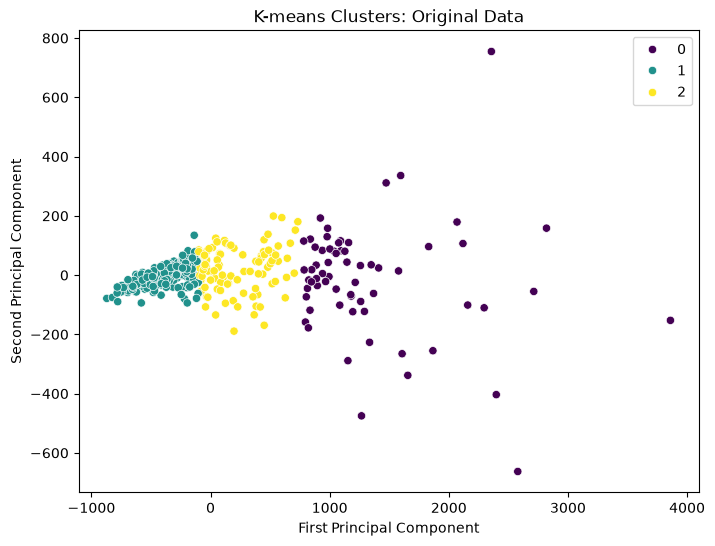

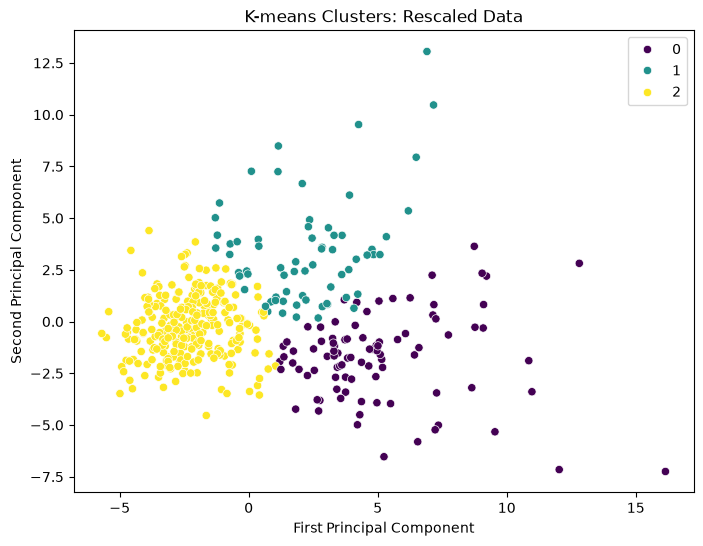

In [12]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_train)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca[:, 0],
                y=X_pca[:, 1],
                hue=indexes_train.flatten(),
                palette='viridis')

plt.xlabel("First Principal Component")
plt.ylabel("Second Principal Component")
plt.title("K-means Clusters: Original Data")
plt.show()


scaler_train = preprocessing.StandardScaler().fit(X_train)
X_train_scale = scaler_train.transform(X_train)

kmeans_scale = faiss.Kmeans(
    X_train_scale.shape[1],
    3,
    niter=100,
    verbose=False,
    seed=0
)

Xtilde_scale = np.float32(X_train_scale)
kmeans_scale.train(Xtilde_scale)

results_scale = kmeans_scale.index.search(Xtilde_scale, 1)
indexes_scale = results_scale[1]

pca_scale = PCA(n_components=2)
X_pca_scale = pca_scale.fit_transform(X_train_scale)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca_scale[:, 0],
                y=X_pca_scale[:, 1],
                hue=indexes_scale.flatten(),
                palette='viridis')

plt.xlabel("First Principal Component")
plt.ylabel("Second Principal Component")
plt.title("K-means Clusters: Rescaled Data")
plt.show()